Esquema temporal de las variables utilizadas en el entrenamiento, prueba y puntuación del modelo

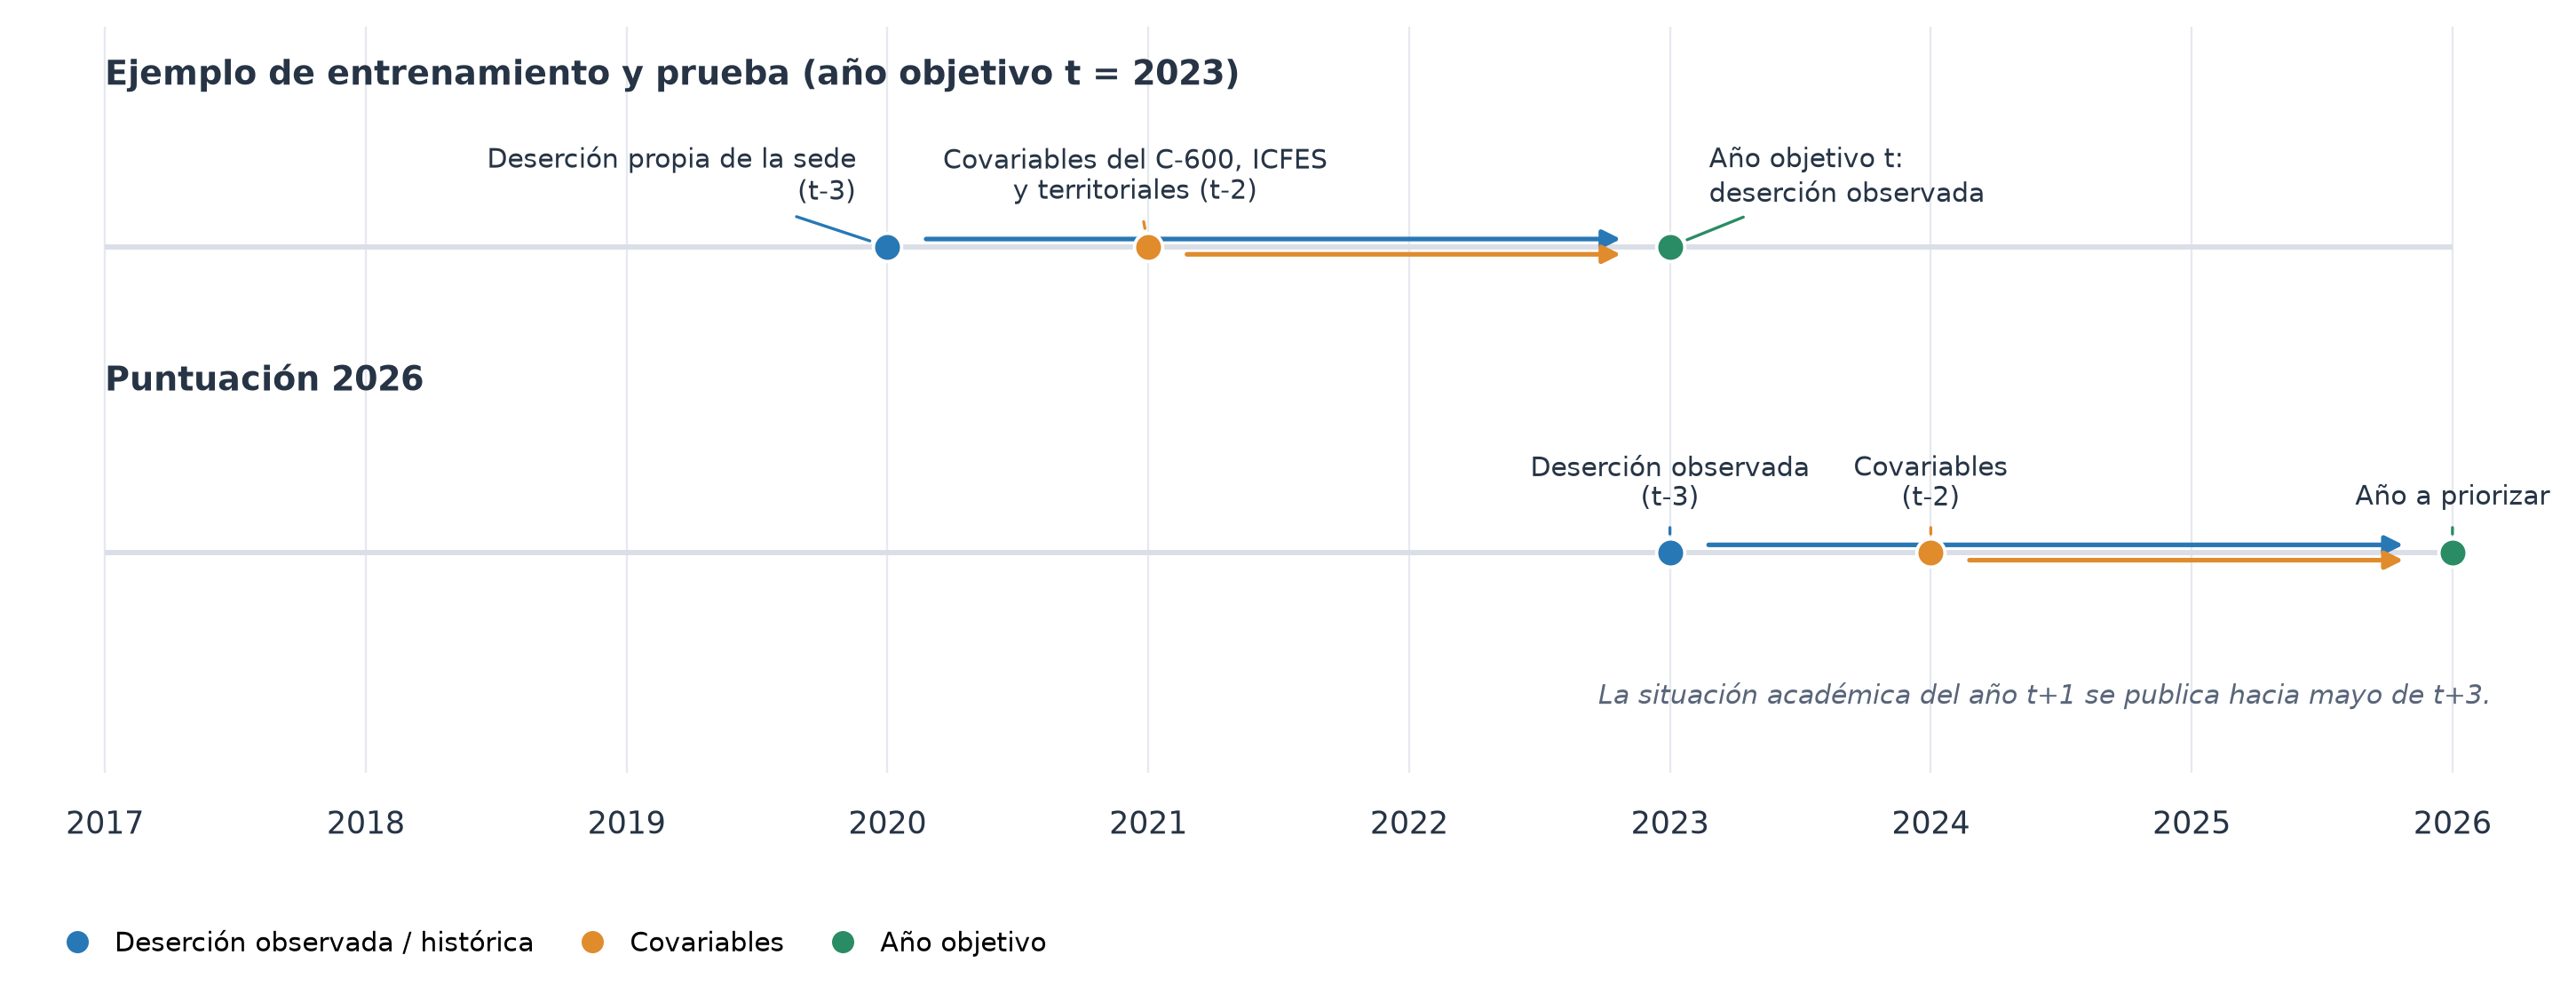

Figure successfully exported to: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\01_Timeline_Training_Scoring.png


In [4]:

# ============================================================
# TIMELINE: TRAINING, TESTING AND 2026 SCORING
# ============================================================

# 1. IMPORTS
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D


# 2. PATHS
OUTPUT_DIR = (
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD"
    r"\Maestria Business A\Proyecto Empresarial"
    r"\Figures\Grafs_Tables_Model"
)

OUTPUT_FILE = os.path.join(
    OUTPUT_DIR,
    "01_Timeline_Training_Scoring.png"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# 3. GENERAL SETTINGS
FIGSIZE = (10, 4)
DPI = 300

YEARS = list(range(2017, 2027))

COLORS = {
    "dropout": "#2878B5",
    "covariates": "#E08B2C",
    "target": "#2A8C65",
    "grid": "#D9DEE7",
    "text": "#263445"
}


# 4. HELPER FUNCTIONS
def add_marker(ax, year, y, color, label,
               text_x, text_y, alignment="center"):

    # Draw timeline marker
    ax.scatter(
        year, y,
        s=58,
        color=color,
        edgecolor="white",
        linewidth=0.9,
        zorder=4
    )

    # Add marker label
    ax.annotate(
        label,
        xy=(year, y),
        xytext=(text_x, text_y),
        ha=alignment,
        va="bottom",
        fontsize=7.1,
        color=COLORS["text"],
        linespacing=1.2,
        arrowprops={
            "arrowstyle": "-",
            "color": color,
            "linewidth": 0.8,
            "shrinkA": 2,
            "shrinkB": 5
        }
    )


def add_arrow(ax, start, end, y, color, vertical_offset=0):

    # Draw directional arrow towards the target year
    arrow = FancyArrowPatch(
        (start + 0.12, y + vertical_offset),
        (end - 0.16, y + vertical_offset),
        arrowstyle="-|>",
        mutation_scale=10,
        linewidth=1.25,
        color=color,
        zorder=2
    )

    ax.add_patch(arrow)


# 5. FIGURE CREATION
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)

y_train = 1.0
y_score = 0.0

ax.set_xlim(2016.7, 2026.3)
ax.set_ylim(-0.72, 1.72)


# 6. TIMELINE AXES
for y in [y_train, y_score]:
    ax.hlines(
        y,
        2017,
        2026,
        color=COLORS["grid"],
        linewidth=1.4,
        zorder=1
    )

ax.set_xticks(YEARS)
ax.set_xticklabels(
    YEARS,
    fontsize=8.5,
    color=COLORS["text"]
)

ax.set_yticks([])
ax.tick_params(axis="x", length=0, pad=10)


# 7. ROW TITLES
ax.text(
    2017,
    1.56,
    "Ejemplo de entrenamiento y prueba (año objetivo t = 2023)",
    fontsize=9.2,
    fontweight="bold",
    color=COLORS["text"],
    ha="left",
    va="center"
)

ax.text(
    2017,
    0.56,
    "Puntuación 2026",
    fontsize=9.2,
    fontweight="bold",
    color=COLORS["text"],
    ha="left",
    va="center"
)


# 8. ROW 1: TRAINING AND TEST EXAMPLE
# Target year: 2023

# Arrows pointing towards the target year
add_arrow(ax, 2020, 2023, y_train, COLORS["dropout"], 0.025)
add_arrow(ax, 2021, 2023, y_train, COLORS["covariates"], -0.025)

# Historical dropout: t-3
add_marker(
    ax, 2020, y_train,
    COLORS["dropout"],
    "Deserción propia de la sede\n(t-3)",
    2019.88, 1.13,
    "right"
)

# Covariates: t-2
add_marker(
    ax, 2021, y_train,
    COLORS["covariates"],
    "Covariables del C-600, ICFES\ny territoriales (t-2)",
    2020.95, 1.13,
    "center"
)

# Observed target
add_marker(
    ax, 2023, y_train,
    COLORS["target"],
    "Año objetivo t:\ndeserción observada",
    2023.15, 1.13,
    "left"
)


# 9. ROW 2: SCORING 2026

# Arrows pointing towards the prioritization year
add_arrow(ax, 2023, 2026, y_score, COLORS["dropout"], 0.025)
add_arrow(ax, 2024, 2026, y_score, COLORS["covariates"], -0.025)

# Historical dropout: t-3
add_marker(
    ax, 2023, y_score,
    COLORS["dropout"],
    "Deserción observada\n(t-3)",
    2023, 0.13,
    "center"
)

# Covariates: t-2
add_marker(
    ax, 2024, y_score,
    COLORS["covariates"],
    "Covariables\n(t-2)",
    2024, 0.13,
    "center"
)

# Prioritization year
add_marker(
    ax, 2026, y_score,
    COLORS["target"],
    "Año a priorizar",
    2026, 0.13,
    "center"
)


# 10. PUBLICATION TIMING ANNOTATION
ax.text(
    2026.15,
    -0.47,
    "La situación académica del año t+1 se publica hacia mayo de t+3.",
    ha="right",
    va="center",
    fontsize=7.1,
    color="#596579",
    style="italic"
)


# 11. LEGEND
legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLORS["dropout"],
        markeredgecolor="white",
        markersize=7,
        label="Deserción observada / histórica"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLORS["covariates"],
        markeredgecolor="white",
        markersize=7,
        label="Covariables"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLORS["target"],
        markeredgecolor="white",
        markersize=7,
        label="Año objetivo"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower left",
    bbox_to_anchor=(0.0, -0.28),
    ncol=3,
    frameon=False,
    fontsize=7.2,
    handletextpad=0.4,
    columnspacing=1.2
)


# 12. FINAL FORMATTING
for spine in ax.spines.values():
    spine.set_visible(False)

ax.grid(
    axis="x",
    color=COLORS["grid"],
    linewidth=0.55,
    alpha=0.65
)

ax.set_axisbelow(True)

fig.subplots_adjust(
    left=0.045,
    right=0.985,
    top=0.94,
    bottom=0.24
)


# 13. EXPORT
fig.savefig(
    OUTPUT_FILE,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Figure successfully exported to: {OUTPUT_FILE}")


Evolución de la deserción escolar y de la proporción de sedes sin deserción observada, según tipo de oferta educativa, 2017-2024

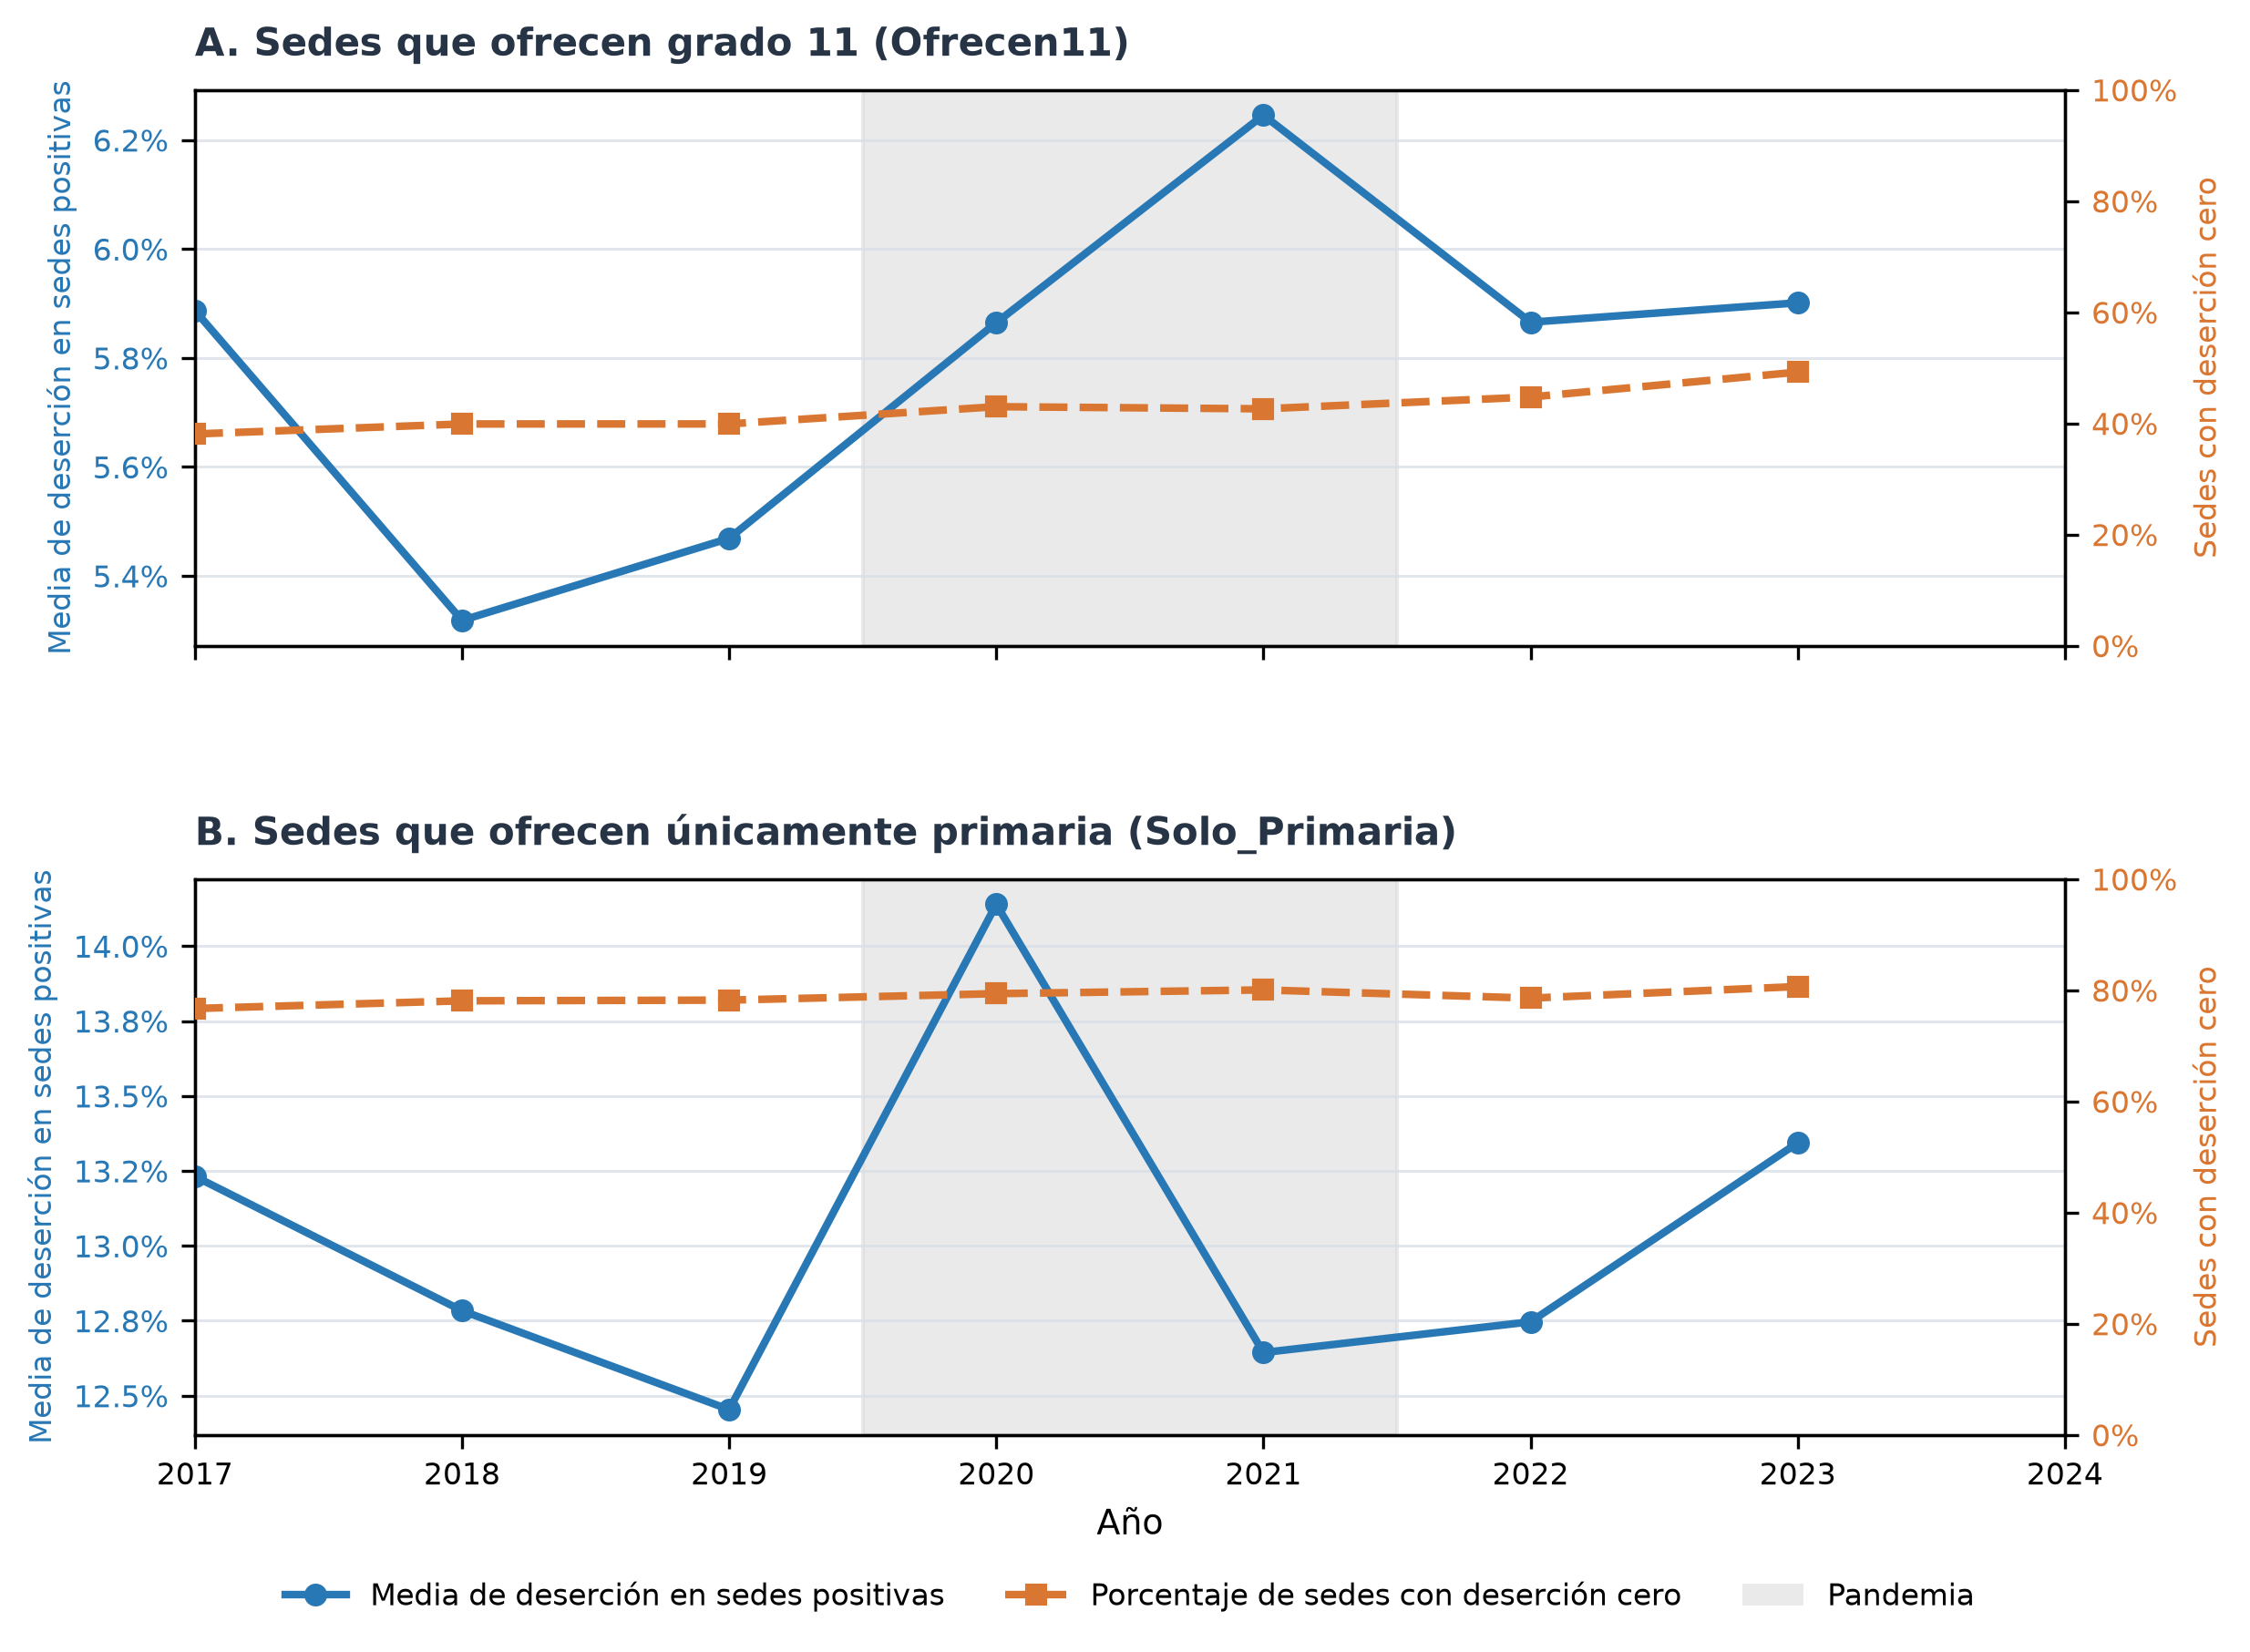


ANNUAL DROPOUT STATISTICS

PANEL: Ofrecen11
---------------------------------------------------------------------------
2017: N=12,295 | Media positiva=5.89% | Ceros=38.09% | Ceros imputados=256
2018: N=12,349 | Media positiva=5.32% | Ceros=39.89% | Ceros imputados=269
2019: N=12,557 | Media positiva=5.47% | Ceros=39.90% | Ceros imputados=149
2020: N=12,679 | Media positiva=5.86% | Ceros=43.00% | Ceros imputados=279
2021: N=12,648 | Media positiva=6.25% | Ceros=42.62% | Ceros imputados=256
2022: N=12,678 | Media positiva=5.87% | Ceros=44.74% | Ceros imputados=255
2023: N=12,647 | Media positiva=5.90% | Ceros=49.22% | Ceros imputados=614
2024: N=0 | Media positiva=N/A | Ceros=N/A | Ceros imputados=0

PANEL: Solo_Primaria
---------------------------------------------------------------------------
2017: N=41,000 | Media positiva=13.23% | Ceros=76.71% | Ceros imputados=6,384
2018: N=40,853 | Media positiva=12.78% | Ceros=78.09% | Ceros imputados=7,100
2019: N=40,970 | Media positiva=12.45

In [6]:

# ============================================================
# FIGURE: SCHOOL DROPOUT TRENDS BY SCHOOL PANEL (2017-2024)
# ============================================================

# 1. IMPORTS
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ============================================================
# 2. PATHS
# ============================================================

DATA_DIR = (
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD"
    r"\Maestria Business A\Proyecto Empresarial"
    r"\Data\Processed"
)

OUTPUT_DIR = (
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD"
    r"\Maestria Business A\Proyecto Empresarial"
    r"\Figures\Grafs_Tables_Model"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

FILE_OFRECEN11 = os.path.join(
    DATA_DIR, "panel_maestro_ofrecen11.csv"
)

FILE_SOLO_PRIMARIA = os.path.join(
    DATA_DIR, "panel_maestro_Solo_Primaria.csv"
)

OUTPUT_FIGURE = os.path.join(
    OUTPUT_DIR, "02_Tendencia_Desercion_Paneles_Maestros.png"
)

OUTPUT_TABLE = os.path.join(
    OUTPUT_DIR, "02_Tendencia_Desercion_Valores_Anuales.csv"
)


# ============================================================
# 3. GENERAL SETTINGS
# ============================================================

YEARS = list(range(2017, 2025))

FIGSIZE = (9, 6)
DPI = 300

# Column names confirmed in the sample workbook
YEAR_COL = "PERIODO_ANIO"
RATE_COL = "TASA_DESERCION_SEDE"
SCHOOL_COL = "SEDE_CODIGO"
IMPUTED_ZERO_COL = "FLAG_DESERCION_SEDE_CERO_IMPUTADO"

COLORS = {
    "positive_mean": "#2878B5",
    "zero_percentage": "#D97732",
    "pandemic": "#D9D9D9",
    "text": "#263445",
    "grid": "#D9DEE7"
}


# ============================================================
# 4. DATA LOADING
# ============================================================

def load_panel(file_path, panel_name):

    # Check whether the input file exists
    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Input file not found: {file_path}"
        )

    # Read CSV while preserving school identifiers
    df = pd.read_csv(
        file_path,
        dtype={SCHOOL_COL: str},
        low_memory=False
    )

    # Validate required columns
    required_columns = [
        YEAR_COL,
        RATE_COL,
        SCHOOL_COL,
        IMPUTED_ZERO_COL
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{panel_name}: Missing columns: {missing_columns}"
        )

    # Convert analytical variables to numeric
    df[YEAR_COL] = pd.to_numeric(
        df[YEAR_COL], errors="coerce"
    )

    df[RATE_COL] = pd.to_numeric(
        df[RATE_COL], errors="coerce"
    )

    df[IMPUTED_ZERO_COL] = pd.to_numeric(
        df[IMPUTED_ZERO_COL], errors="coerce"
    )

    # Keep the requested observation period
    df = df[df[YEAR_COL].isin(YEARS)].copy()

    # Validate that each school has only one record per year
    duplicated = df.duplicated(
        subset=[SCHOOL_COL, YEAR_COL],
        keep=False
    )

    if duplicated.any():
        examples = df.loc[
            duplicated, [SCHOOL_COL, YEAR_COL]
        ].head(10)

        raise ValueError(
            f"{panel_name}: Duplicate school-year records found.\n"
            f"Examples:\n{examples.to_string(index=False)}"
        )

    # Exclude observations without an available dropout rate
    df = df.dropna(subset=[RATE_COL, YEAR_COL]).copy()

    # Validate dropout rates
    if ((df[RATE_COL] < 0) | (df[RATE_COL] > 1)).any():
        raise ValueError(
            f"{panel_name}: Dropout rates outside the [0, 1] range."
        )

    return df


# ============================================================
# 5. ANNUAL STATISTICS
# ============================================================

def calculate_annual_statistics(df, panel_name):

    records = []

    for year in YEARS:

        year_df = df[df[YEAR_COL] == year].copy()

        n_schools = len(year_df)

        if n_schools == 0:
            records.append({
                "PANEL": panel_name,
                "YEAR": year,
                "N_SEDES": 0,
                "N_SEDES_POSITIVAS": 0,
                "N_SEDES_CERO": 0,
                "N_CEROS_IMPUTADOS": 0,
                "MEAN_POSITIVE_DROPOUT": np.nan,
                "PCT_ZERO_DROPOUT": np.nan
            })
            continue

        # Identify positive and zero dropout rates
        positive_rates = year_df.loc[
            year_df[RATE_COL] > 0, RATE_COL
        ]

        zero_schools = year_df[RATE_COL] == 0

        # Count imputed zeros among all zero observations
        imputed_zeros = (
            zero_schools
            & (year_df[IMPUTED_ZERO_COL] == 1)
        ).sum()

        # Calculate annual statistics
        mean_positive = (
            positive_rates.mean()
            if len(positive_rates) > 0
            else np.nan
        )

        pct_zero = zero_schools.mean() * 100

        records.append({
            "PANEL": panel_name,
            "YEAR": year,
            "N_SEDES": n_schools,
            "N_SEDES_POSITIVAS": len(positive_rates),
            "N_SEDES_CERO": int(zero_schools.sum()),
            "N_CEROS_IMPUTADOS": int(imputed_zeros),
            "MEAN_POSITIVE_DROPOUT": mean_positive,
            "PCT_ZERO_DROPOUT": pct_zero
        })

    return pd.DataFrame(records)


# ============================================================
# 6. PLOT FUNCTION
# ============================================================

def plot_panel(ax, df_stats, panel_title):

    # Create the secondary axis
    ax_right = ax.twinx()

    years = df_stats["YEAR"]

    mean_positive = df_stats[
        "MEAN_POSITIVE_DROPOUT"
    ]

    pct_zero = df_stats[
        "PCT_ZERO_DROPOUT"
    ]

    # Highlight pandemic years: 2020 and 2021
    ax.axvspan(
        2019.5,
        2021.5,
        color=COLORS["pandemic"],
        alpha=0.55,
        zorder=0
    )

    # Left axis: mean dropout rate among positive schools
    ax.plot(
        years,
        mean_positive,
        color=COLORS["positive_mean"],
        linewidth=2,
        marker="o",
        markersize=5,
        label="Media de deserción en sedes positivas",
        zorder=3
    )

    # Right axis: percentage of schools with zero dropout
    ax_right.plot(
        years,
        pct_zero,
        color=COLORS["zero_percentage"],
        linewidth=2,
        marker="s",
        markersize=5,
        linestyle="--",
        label="Sedes con deserción cero",
        zorder=3
    )

    # Panel title
    ax.set_title(
        panel_title,
        fontsize=10,
        fontweight="bold",
        color=COLORS["text"],
        loc="left",
        pad=9
    )

    # X-axis
    ax.set_xlim(2017, 2024)
    ax.set_xticks(YEARS)
    ax.set_xticklabels(YEARS, fontsize=8)

    # Left Y-axis
    ax.yaxis.set_major_formatter(
        mtick.PercentFormatter(xmax=1, decimals=1)
    )

    ax.set_ylabel(
        "Media de deserción en sedes positivas",
        fontsize=8,
        color=COLORS["positive_mean"]
    )

    ax.tick_params(
        axis="y",
        labelcolor=COLORS["positive_mean"],
        labelsize=8
    )

    # Right Y-axis
    ax_right.set_ylim(0, 100)

    ax_right.yaxis.set_major_formatter(
        mtick.PercentFormatter(xmax=100, decimals=0)
    )

    ax_right.set_ylabel(
        "Sedes con deserción cero",
        fontsize=8,
        color=COLORS["zero_percentage"]
    )

    ax_right.tick_params(
        axis="y",
        labelcolor=COLORS["zero_percentage"],
        labelsize=8
    )

    # Grid and formatting
    ax.grid(
        axis="y",
        color=COLORS["grid"],
        linewidth=0.7,
        alpha=0.8
    )

    ax.set_axisbelow(True)

    return ax_right


# ============================================================
# 7. MAIN EXECUTION
# ============================================================

# Load both master panels
df_ofrecen11 = load_panel(
    FILE_OFRECEN11,
    "Ofrecen11"
)

df_solo_primaria = load_panel(
    FILE_SOLO_PRIMARIA,
    "Solo_Primaria"
)

# Calculate annual statistics
stats_ofrecen11 = calculate_annual_statistics(
    df_ofrecen11,
    "Ofrecen11"
)

stats_solo_primaria = calculate_annual_statistics(
    df_solo_primaria,
    "Solo_Primaria"
)

# Combine annual statistics
stats_all = pd.concat(
    [stats_ofrecen11, stats_solo_primaria],
    ignore_index=True
)

# Export annual statistics
stats_all.to_csv(
    OUTPUT_TABLE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. FIGURE
# ============================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=FIGSIZE,
    dpi=DPI,
    sharex=True
)

# First panel: schools offering grade 11
plot_panel(
    axes[0],
    stats_ofrecen11,
    "A. Sedes que ofrecen grado 11 (Ofrecen11)"
)

# Second panel: primary-only schools
plot_panel(
    axes[1],
    stats_solo_primaria,
    "B. Sedes que ofrecen únicamente primaria (Solo_Primaria)"
)

# Common X-axis label
axes[1].set_xlabel(
    "Año",
    fontsize=9
)

# Shared legend
legend_elements = [
    Line2D(
        [0], [0],
        color=COLORS["positive_mean"],
        marker="o",
        linewidth=2,
        markersize=5,
        label="Media de deserción en sedes positivas"
    ),
    Line2D(
        [0], [0],
        color=COLORS["zero_percentage"],
        marker="s",
        linestyle="--",
        linewidth=2,
        markersize=5,
        label="Porcentaje de sedes con deserción cero"
    ),
    Patch(
        facecolor=COLORS["pandemic"],
        alpha=0.55,
        label="Pandemia"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),
    ncol=3,
    frameon=False,
    fontsize=8
)

# Final layout
fig.subplots_adjust(
    left=0.12,
    right=0.88,
    top=0.95,
    bottom=0.13,
    hspace=0.42
)

# Export figure
fig.savefig(
    OUTPUT_FIGURE,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# 9. PRINT RESULTS FOR THESIS WRITING
# ============================================================

print("\n" + "=" * 75)
print("ANNUAL DROPOUT STATISTICS")
print("=" * 75)

for panel_name in ["Ofrecen11", "Solo_Primaria"]:

    panel_stats = stats_all[
        stats_all["PANEL"] == panel_name
    ].copy()

    print(f"\nPANEL: {panel_name}")
    print("-" * 75)

    for _, row in panel_stats.iterrows():

        mean_value = row["MEAN_POSITIVE_DROPOUT"]
        zero_value = row["PCT_ZERO_DROPOUT"]

        mean_text = (
            f"{mean_value * 100:.2f}%"
            if pd.notna(mean_value)
            else "N/A"
        )

        zero_text = (
            f"{zero_value:.2f}%"
            if pd.notna(zero_value)
            else "N/A"
        )

        print(
            f"{int(row['YEAR'])}: "
            f"N={int(row['N_SEDES']):,} | "
            f"Media positiva={mean_text} | "
            f"Ceros={zero_text} | "
            f"Ceros imputados={int(row['N_CEROS_IMPUTADOS']):,}"
        )

print("\n" + "=" * 75)
print("OUTPUT FILES")
print("=" * 75)

print(f"Figure: {OUTPUT_FIGURE}")
print(f"Annual statistics: {OUTPUT_TABLE}")
